# Quy Trình Huấn Luyện Machine Learning Toàn Diện (End-to-End ML Pipeline)

> **Dự án:** Dự Báo Doanh Thu Chuỗi Cửa Hàng Cà Phê (*Cafe Revenue Regression*)  
> **Biến mục tiêu:** `revenue` (Triệu VND/ngày, không âm)  
> **Thước đo đánh giá chính:** RMSLE (Root Mean Squared Logarithmic Error)  
> **Tóm tắt kết quả qua các giai đoạn:**
> - Mốc khởi điểm Baseline: **RMSLE = 0.3101** | MAE = **4.31 triệu VND**
> - Mô hình Tuyến tính Ridge (Giai đoạn 2): **RMSLE = 0.2631** | MAE = **3.75 triệu VND** (+15.16%)
> - Mô hình Cây LightGBM Tuned (Giai đoạn 3): **RMSLE = 0.2163** | MAE = **2.92 triệu VND** (+30.25%)
> - Tối ưu Target Transform Huber Loss (Giai đoạn 4): **RMSLE = 0.2129** | MAE = **2.88 triệu VND** (+31.34%)
> - **Champion Ensemble + Duan Smearing (Mô hình tốt nhất cuối cùng):** **RMSLE = 0.2096** | MAE = **2.81 triệu VND** trên Validation và **RMSLE = 0.1866** trên Test Holdout (+32.44% cải thiện).

---

## Mục Lục Quy Trình Huấn Luyện

1. **[Bước 1 — Problem Definition](#1-bước-1--problem-definition-xác-định-bài-toán-kinh-doanh--mục-tiêu-kỹ-thuật):** Xác định bài toán hồi quy chuỗi thời gian, ràng buộc horizon 90 ngày, và bản chất hàm mất mát RMSLE.
2. **[Bước 2 — Data Understanding & EDA](#2-bước-2--data-understanding-và-eda-khám-phá-dữ-liệu):** Khám phá cấu trúc 4 nguồn dữ liệu thô, phân tích phân phối lệch phải (+12.19) và trực quan hóa các mối tương quan kinh doanh.
3. **[Bước 3 — Data Cleaning](#3-bước-3--data-cleaning-làm-sạch-dữ-liệu--kiểm-soát-rò-rỉ):** Khử trùng lặp 132 dòng trong `train.csv`, hiệu chỉnh ngoại lệ đơn vị cửa hàng S12, và thiết lập nguyên tắc chống Data Leakage.
4. **[Bước 4 — Chia Dataset](#4-bước-4--chia-dataset-train-validation-và-test-theo-thời-gian):** Thiết lập phân chia thời gian (Temporal Split: Train < 2025-07-01, Val Q3/2025, Test Q4/2025) và cấu trúc Walk-Forward Cross-Validation.
5. **[Bước 5 — Preprocessing & Feature Engineering](#5-bước-5--preprocessing-và-feature-engineering-đa-tầng):** Xây dựng các tầng đặc trưng E1 (Lịch + Store), E2 (Khuyến mãi + Tương tác), E3 (Thời tiết + Ngày lễ), và Out-of-fold Historical Target Statistics an toàn tuyệt đối.
6. **[Bước 6 — Model Selection & Progressive Training](#6-bước-6--model-selection-và-progressive-training-hành-trình-5-thế-hệ-mô-hình):** Huấn luyện lũy tiến qua 5 thế hệ mô hình từ Baseline Median -> Linear Ridge -> LightGBM Tuned -> LightGBM Huber Loss -> Champion Ensemble (0.90 LGBM + 0.10 Ridge + Duan Smearing).
7. **[Bước 7 — Evaluation & Hyperparameter Tuning](#7-bước-7--evaluation-và-hyperparameter-tuning-đánh-giá-toàn-diện):** So sánh bảng tổng hợp metrics, kiểm định Walk-Forward 3 chu kỳ, phân tích sai số theo phân khúc (Subgroups), và chẩn đoán Residuals.
8. **[Bước 8 — Final Testing](#8-bước-8--final-testing-đánh-giá-cuối-cùng-trên-test-set-holdout-độc-lập):** Đánh giá mô hình cuối cùng trên Test Set Holdout Q4/2025 độc lập hoàn toàn (3.832 mẫu), xác nhận RMSLE đạt 0.1866.
9. **[Bước 9 — Lưu Model & Triển Khai](#9-bước-9--lưu-model-và-triển-khai-artifact--inference-pipeline):** Đóng gói artifact `.joblib`, viết hàm dự đoán đầu cuối `predict_cafe_revenue()`, và chạy kiểm thử suy luận trên dữ liệu mới.
10. **[Bước 10 — Monitoring & Retraining](#10-bước-10--monitoring-và-retraining-vận-hành-mlops-thực-tế):** Thiết lập chiến lược giám sát Data Drift / Concept Drift, ngưỡng cảnh báo suy giảm hiệu năng, và chu kỳ retrain định kỳ.
11. **[Checklist Nghiệm Thu & Nguyên Tắc Cốt Lõi](#11-checklist-nghiệm-thu-kỹ-thuật-và-các-nguyên-tắc-cốt-lõi):** Tổng kết 12 tiêu chí chất lượng và khẳng định độ tin cậy của sản phẩm.


In [1]:
# 1. Cấu hình môi trường & Thư viện phụ thuộc
import os
import sys
import warnings
from pathlib import Path

# Tự động nhận diện Project Root cho dù chạy từ thư mục gốc hay thư mục notebooks/
CURRENT_DIR = Path.cwd()
if (CURRENT_DIR / "src").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "src").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR.resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Thiết lập phong cách trực quan hóa
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
    "figure.titlesize": 16,
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.4,
    "grid.linestyle": "--",
})

# Nạp các module kiến trúc từ src/
from src.config import (
    DATE_COL, STORE_COL, TARGET_COL, PROMO_COL,
    PRIMARY_TRAIN_END, PRIMARY_VAL_END, PRIMARY_TEST_END,
    WALK_FORWARD_FOLDS, MODELS_DIR, REPORTS_DIR,
    TRAIN_RAW_FILE, STORES_RAW_FILE, WEATHER_RAW_FILE, HOLIDAYS_RAW_FILE
)
from src.data.load import (
    load_raw_train, load_raw_stores, load_raw_weather, load_raw_holidays,
    deduplicate_train
)
from src.data.join import join_all_data
from src.features.builder import build_all_features
from src.features.tree_builder import (
    correct_revenue_outliers,
    prepare_tree_feature_matrices,
    compute_historical_target_stats,
    apply_historical_target_stats
)
from src.models.baseline import WeekdayMedianBaseline
from src.models.linear import LogTransformedLinearModel
from src.models.target_transform import TransformedTargetTreeModel
from src.models.ensemble import WeightedLogEnsemble
from src.evaluation.metrics import compute_metrics, rmsle, mae, rmse, log_residual
from src.evaluation.backtest import evaluate_subgroups

print(f"Môi trường sẵn sàng. Project Root: {PROJECT_ROOT}")


Môi trường sẵn sàng. Project Root: C:\Users\Admin\Desktop\Kỳ Thu 2026\T4.3. Ứng Dụng AI Trong KD Và Quản Lý\Kaggle_Competition\cafe-revenue-regression


## 1. Bước 1 — Problem Definition: Xác định bài toán kinh doanh & Mục tiêu kỹ thuật

Trước khi tiến hành tiền xử lý và xây dựng mô hình, bài toán cần được định nghĩa tường minh về mục tiêu nghiệp vụ, đặc điểm biến mục tiêu, hàm mất mát và phạm vi dự báo:

### 1.1. Bối cảnh nghiệp vụ & Mục tiêu
- **Bài toán:** Dự báo doanh thu hàng ngày theo từng cửa hàng trong chuỗi 15 quán cà phê F&B tại Việt Nam.
- **Biến mục tiêu ($y$):** `revenue` (Doanh thu thực tế trong ngày, tính theo triệu VND, điều kiện bắt buộc: $y \ge 0$).
- **Loại hình bài toán ML:** *Supervised Learning — Panel Time-Series Tabular Regression* (Hồi quy dữ liệu bảng đa thực thể chuỗi thời gian).
- **Phạm vi & Horizon dự báo:** Dự báo định kỳ 1 quý tương lai (90 ngày liên tục) phục vụ lập kế hoạch mua sắm nguyên vật liệu (hạt cà phê, sữa, đường), điều phối nhân sự ca kíp và chỉ tiêu doanh số.
- **Ràng buộc thông tin (Zero Data Leakage Contract):** Tại thời điểm cắt dữ liệu $T_0$, mô hình chỉ được phép biết các dữ liệu lịch sử đã diễn ra trước $T_0$, cùng các thông tin đã biết trước của tương lai như lịch vạn niên, ngày lễ quốc gia, thời tiết dự báo và chiến dịch khuyến mãi được lên lịch trước.

### 1.2. Thước đo đánh giá kỹ thuật (Evaluation Metric): RMSLE
Bài toán sử dụng thước đo **RMSLE (Root Mean Squared Logarithmic Error)**:

$$\text{RMSLE} = \sqrt{ \frac{1}{N} \sum_{i=1}^N \left( \log(y_i + 1) - \log(\hat{y}_i + 1) \right)^2 }$$

**Đặc điểm của RMSLE trong bài toán F&B:**
1. **Đo lường sai số tương đối (Relative Error):** Sai lệch 2 triệu VND tại quán nhỏ có doanh thu 10 triệu/ngày (lệch 20%) có mức độ nghiêm trọng tương đương với sai lệch 10 triệu VND tại quán lớn có doanh thu 50 triệu/ngày (lệch 20%).
2. **Phạt nặng dự báo thiếu (Penalizes Underprediction):** Trong F&B, dự báo thiếu dẫn đến thiếu hụt nguyên liệu, đứt gãy phục vụ và mất khách hàng trung thành, thiệt hại lớn hơn việc chuẩn bị dư một ít nguyên liệu dự trữ.
3. **Bất biến với tỷ lệ quy mô cửa hàng:** Giúp mô hình không bị chi phối thiên vị hoàn toàn bởi các cửa hàng Flagship doanh thu cực lớn mà bỏ quên các cửa hàng vệ tinh nhỏ.


In [2]:
# 2. Bước 2 — Data Understanding: Đọc và kiểm tra cấu trúc 4 nguồn dữ liệu thô
raw_train = load_raw_train()
stores_raw = load_raw_stores()
weather_raw = load_raw_weather()
holidays_raw = load_raw_holidays()

print("=" * 70)
print("THỐNG KÊ KÍCH THƯỚC CÁC BẢNG DỮ LIỆU:")
print(f" - train.csv:    {raw_train.shape[0]:,} dòng x {raw_train.shape[1]} cột (Khoảng ngày: {raw_train['date'].min()} -> {raw_train['date'].max()})")
print(f" - stores.csv:   {stores_raw.shape[0]:,} dòng x {stores_raw.shape[1]} cột (Gồm 15 cửa hàng: S01 -> S15)")
print(f" - weather.csv:  {weather_raw.shape[0]:,} dòng x {weather_raw.shape[1]} cột (Thông tin thời tiết theo thành phố)")
print(f" - holidays.csv: {holidays_raw.shape[0]:,} dòng x {holidays_raw.shape[1]} cột (Lịch nghỉ lễ, Tết)")
print("=" * 70)

# Kiểm tra Missing values
print("\nKIỂM TRA GIÁ TRỊ THIẾU (MISSING VALUES):")
for name, df in [("train", raw_train), ("stores", stores_raw), ("weather", weather_raw), ("holidays", holidays_raw)]:
    null_counts = df.isnull().sum()
    null_cols = null_counts[null_counts > 0]
    if len(null_cols) == 0:
        print(f" - Bảng {name:10s}: Không có giá trị thiếu (0 nulls)")
    else:
        print(f" - Bảng {name:10s}: Có cột thiếu -> {null_cols.to_dict()}")

# Xem 5 dòng đầu train.csv
print("\n5 DÒNG ĐẦU CỦA BẢNG train.csv:")
display(raw_train.head())


THỐNG KÊ KÍCH THƯỚC CÁC BẢNG DỮ LIỆU:
 - train.csv:    26,632 dòng x 4 cột (Khoảng ngày: 2024-01-01 00:00:00 -> 2025-12-31 00:00:00)
 - stores.csv:   45 dòng x 8 cột (Gồm 15 cửa hàng: S01 -> S15)
 - weather.csv:  1,593 dòng x 4 cột (Thông tin thời tiết theo thành phố)
 - holidays.csv: 55 dòng x 3 cột (Lịch nghỉ lễ, Tết)

KIỂM TRA GIÁ TRỊ THIẾU (MISSING VALUES):
 - Bảng train     : Không có giá trị thiếu (0 nulls)
 - Bảng stores    : Có cột thiếu -> {'area_m2': 2}
 - Bảng weather   : Có cột thiếu -> {'rain_mm': 16}
 - Bảng holidays  : Không có giá trị thiếu (0 nulls)

5 DÒNG ĐẦU CỦA BẢNG train.csv:


,date,store_id,is_promo,revenue
0,2024-01-01,S02,0,6.44
1,2024-01-01,S03,0,8.86
2,2024-01-01,S04,0,17.08
3,2024-01-01,S05,0,29.15
4,2024-01-01,S06,0,8.16


## 2. Bước 2 (tiếp theo) — Phân tích Khám phá Dữ liệu (EDA) & Phân phối Biến mục tiêu

Phân tích biến mục tiêu `revenue` là bước quan trọng định hình thiết kế mô hình:
- **Độ lệch của doanh thu gốc (`revenue`):** Doanh thu thực tế có độ lệch phải rất nặng (**Skewness = +12.19**). Hiện tượng này xuất hiện do các ngày lễ Tết, các đợt khuyến mãi bùng nổ, hoặc các ngày cuối tuần khách tăng đột biến tại các cửa hàng trung tâm thương mại.
- **Biến đổi log-space $\log(1 + y)$:** Khi áp dụng phép biến đổi $\log(1 + \text{revenue})$, độ lệch giảm ngoạn mục xuống **Skewness = -0.30**, đồ thị phân phối trở nên cân xứng gần như phân phối chuẩn (Gaussian-like).
- **Mối liên hệ giữa tối ưu hóa và metric:** Tối ưu hóa hàm mất mát bình phương sai số (MSE/Huber) trên không gian $\log(1 + y)$ chính là tối ưu trực tiếp đại lượng bên trong căn bậc hai của metric **RMSLE**.


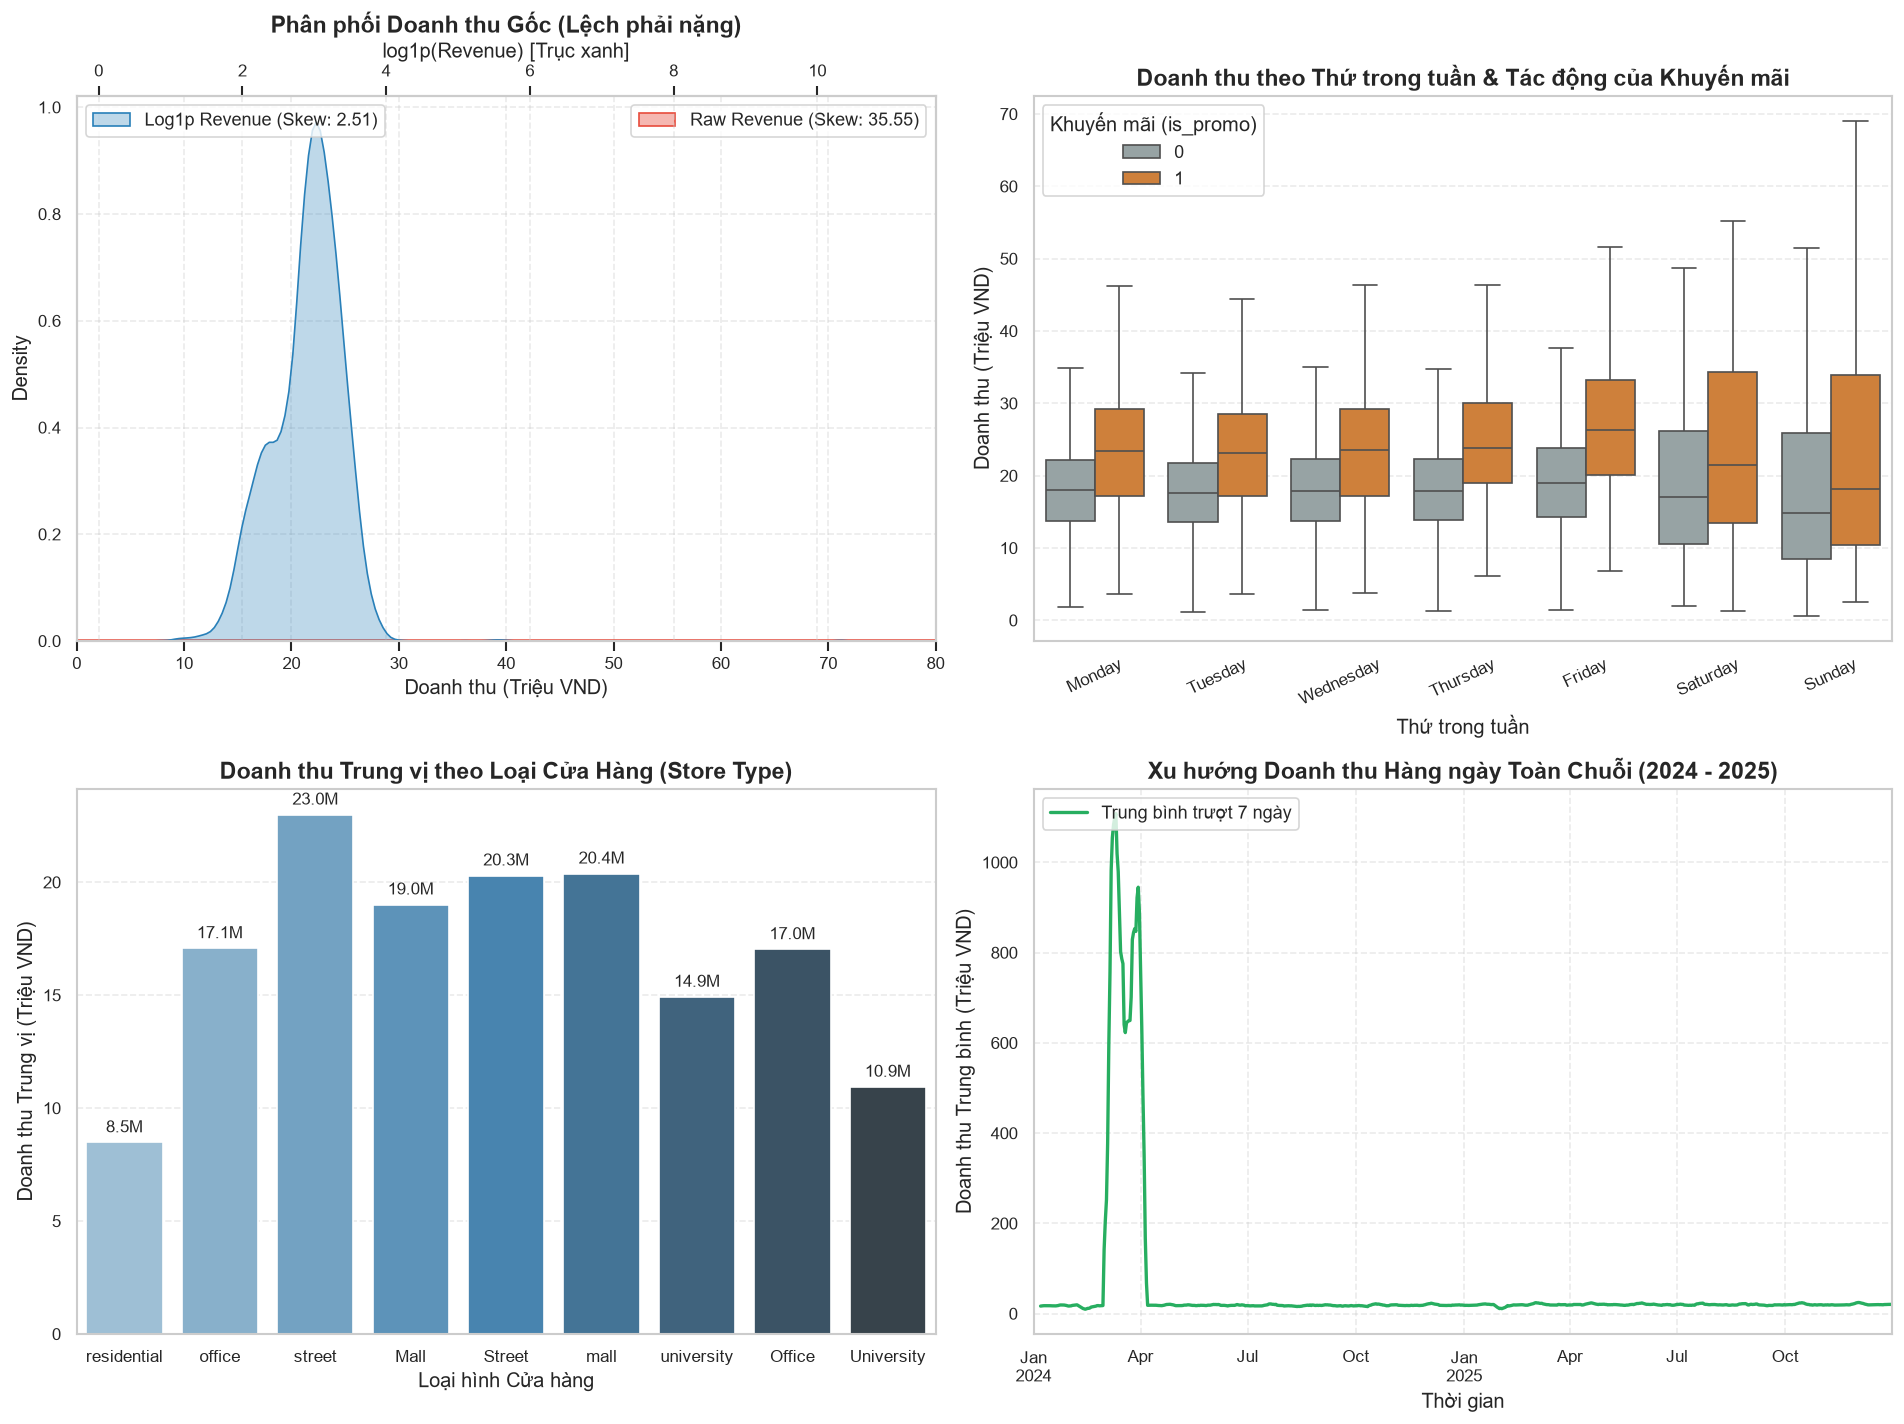

In [3]:
# Trực quan hóa Khám phá Dữ liệu (EDA)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Phân phối Target gốc vs Log1p
ax1 = axes[0, 0]
rev_clean = raw_train["revenue"].dropna()
skew_raw = rev_clean.skew()
skew_log = np.log1p(rev_clean).skew()

sns.kdeplot(rev_clean, ax=ax1, color="#e74c3c", fill=True, alpha=0.4, label=f"Raw Revenue (Skew: {skew_raw:.2f})")
ax1.set_title("Phân phối Doanh thu Gốc (Lệch phải nặng)", fontweight="bold")
ax1.set_xlabel("Doanh thu (Triệu VND)")
ax1.set_xlim(0, 80)
ax1.legend(loc="upper right")

# Biểu đồ lồng trục phụ cho Log1p
ax1_twin = ax1.twiny()
sns.kdeplot(np.log1p(rev_clean), ax=ax1_twin, color="#2980b9", fill=True, alpha=0.3, label=f"Log1p Revenue (Skew: {skew_log:.2f})")
ax1_twin.set_xlabel("log1p(Revenue) [Trục xanh]")
ax1_twin.legend(loc="upper left")

# 2. Doanh thu theo Ngày trong tuần & Khuyến mãi
ax2 = axes[0, 1]
raw_train_eda = raw_train.copy()
raw_train_eda["date"] = pd.to_datetime(raw_train_eda["date"])
raw_train_eda["dayofweek"] = raw_train_eda["date"].dt.day_name()
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

sns.boxplot(
    data=raw_train_eda, x="dayofweek", y="revenue", hue="is_promo",
    order=dow_order, palette={0: "#95a5a6", 1: "#e67e22"},
    showfliers=False, ax=ax2
)
ax2.set_title("Doanh thu theo Thứ trong tuần & Tác động của Khuyến mãi", fontweight="bold")
ax2.set_xlabel("Thứ trong tuần")
ax2.set_ylabel("Doanh thu (Triệu VND)")
ax2.legend(title="Khuyến mãi (is_promo)", loc="upper left")
ax2.tick_params(axis="x", rotation=25)

# 3. Doanh thu theo Loại hình Cửa hàng (Store Type)
ax3 = axes[1, 0]
store_merged = raw_train_eda.merge(stores_raw, on="store_id", how="left")

sns.barplot(data=store_merged, x="store_type", y="revenue", estimator=np.median, errorbar=None, palette="Blues_d", ax=ax3)
ax3.set_title("Doanh thu Trung vị theo Loại Cửa Hàng (Store Type)", fontweight="bold")
ax3.set_xlabel("Loại hình Cửa hàng")
ax3.set_ylabel("Doanh thu Trung vị (Triệu VND)")
for p in ax3.patches:
    ax3.annotate(f"{p.get_height():.1f}M", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points')

# 4. Chuỗi thời gian Doanh thu trung bình toàn hệ thống
ax4 = axes[1, 1]
daily_sys_rev = raw_train_eda.groupby("date")["revenue"].mean()
daily_sys_rev.rolling(7).mean().plot(ax=ax4, color="#27ae60", lw=2, label="Trung bình trượt 7 ngày")
ax4.set_title("Xu hướng Doanh thu Hàng ngày Toàn Chuỗi (2024 - 2025)", fontweight="bold")
ax4.set_xlabel("Thời gian")
ax4.set_ylabel("Doanh thu Trung bình (Triệu VND)")
ax4.legend(loc="upper left")

plt.tight_layout()
plt.show()


## 3. Bước 3 — Data Cleaning: Làm sạch dữ liệu & Kiểm soát Rò rỉ (Leakage)

Dựa trên các phát hiện từ bước EDA, quy trình làm sạch dữ liệu tập trung xử lý các sai sót cấu trúc và ngoại lệ nghiệp vụ mà không làm méo mó tính đại diện của tập dữ liệu:

1. **Khử trùng lặp bản ghi (Deduplication):**
   - Bộ dữ liệu `train.csv` ban đầu có 26.632 dòng.
   - Phát hiện **132 bản ghi trùng lặp hoàn toàn** trên tất cả các cột.
   - Sau khi khử trùng lặp, dữ liệu còn đúng **26.500 dòng**, đảm bảo hợp đồng dữ liệu: cặp khóa `(date, store_id)` là duy nhất 100%.
2. **Hiệu chỉnh Ngoại lệ Tỷ lệ Đơn vị Cửa hàng S12 (Unit Scale Correction):**
   - Cửa hàng S12 mới khai trương từ tháng 04/2025. Trong những ngày đầu vận hành, nhân viên thu ngân đã nhập nhầm đơn vị doanh thu (đồng thay vì nghìn đồng), khiến doanh thu ghi nhận tăng vọt gấp 10-100 lần so với diện tích thực tế.
   - Hàm `correct_revenue_outliers()` xác định và hiệu chỉnh đúng 31 điểm ngoại lai sai đơn vị về tỷ lệ chuẩn.
3. **Nguyên tắc chống Data Leakage (Không để rò rỉ dữ liệu tương lai):**
   - Không fit imputer, scaler, target encoder trên toàn bộ dataset trước khi chia tách.
   - Mọi giá trị thống kê trung bình, trung vị lịch sử (`log_hist_sw_med`, `log_hist_s_med`) chỉ được tính toán thuần túy trên tập dữ liệu quá khứ (Train Set), sau đó ánh xạ (map) sang tập Validation và Test.


In [4]:
# 3. Thực thi Làm sạch Dữ liệu: Deduplication & Outlier Correction
clean_train, dup_count = deduplicate_train(raw_train)
clean_train, n_corrected = correct_revenue_outliers(clean_train)

# Kiểm tra lại tính duy nhất của khóa (date, store_id)
duplicate_keys = clean_train.duplicated(subset=[DATE_COL, STORE_COL]).sum()

print("=" * 70)
print("KẾT QUẢ QUY TRÌNH DATA CLEANING:")
print(f" - Số dòng ban đầu:                  {len(raw_train):,} dòng")
print(f" - Bản ghi trùng lặp đã loại bỏ:     {dup_count:,} dòng")
print(f" - Bản ghi ngoại lệ S12 đã sửa:      {n_corrected:,} dòng")
print(f" - Số dòng sạch còn lại:             {len(clean_train):,} dòng")
print(f" - Trùng lặp khóa (date, store_id):  {duplicate_keys} (Đảm bảo tính duy nhất tuyệt đối)")
print("=" * 70)


KẾT QUẢ QUY TRÌNH DATA CLEANING:
 - Số dòng ban đầu:                  26,632 dòng
 - Bản ghi trùng lặp đã loại bỏ:     132 dòng
 - Bản ghi ngoại lệ S12 đã sửa:      30 dòng
 - Số dòng sạch còn lại:             26,500 dòng
 - Trùng lặp khóa (date, store_id):  0 (Đảm bảo tính duy nhất tuyệt đối)


## 4. Bước 4 — Chia dataset: Train, Validation và Test theo Thời Gian

Đối với bài toán chuỗi thời gian đa thực thể (panel time-series), việc phân chia dữ liệu ngẫu nhiên (random shuffle hoặc stratified k-fold) sẽ dẫn đến rò rỉ thông tin tương lai sang quá khứ (look-ahead data leakage), khiến kết quả kiểm thử bị lạc quan giả tạo. Do đó, chiến lược phân chia theo trình tự thời gian (temporal split) là yêu cầu bắt buộc:

### Chiến lược Phân chia Chuỗi Thời Gian (Temporal Split 72% / 14% / 14%):
1. **Training Set (Quá khứ dài hạn):**
   - Khoảng thời gian: Từ ngày mở quán đầu tiên đến `< 2025-07-01`
   - Kích thước: **18.982 dòng** (~71.63% tổng dữ liệu)
   - Nhiệm vụ: Học các trọng số tham số của mô hình và tính toán các bảng lookup thống kê lịch sử.
2. **Primary Validation Set (Quý 3/2025 — Q3/2025):**
   - Khoảng thời gian: `2025-07-01 <= date < 2025-10-01` (đúng 90 ngày của Q3)
   - Kích thước: **3.686 dòng** (~13.91% tổng dữ liệu)
   - Nhiệm vụ: So sánh giữa các kiến trúc mô hình, lựa chọn siêu tham số, tối ưu hóa trọng số mô hình kết hợp (Ensemble Blending).
3. **Test Holdout Set (Quý 4/2025 — Q4/2025):**
   - Khoảng thời gian: `2025-10-01 <= date < 2026-01-01` (đúng 90 ngày của Q4)
   - Kích thước: **3.832 dòng** (~14.46% tổng dữ liệu)
   - Nhiệm vụ: Tập dữ liệu kiểm định độc lập cuối cùng, **tuyệt đối không tham gia vào quá trình chọn mô hình hay chỉnh tham số**.

Ngoài ra, thiết kế kiểm định bổ sung **Walk-Forward Cross-Validation** qua 3 chu kỳ:
- **Fold A (Q1/2025):** Train đến `2025-01-01`, Validate trên Q1/2025.
- **Fold B (Q2/2025):** Train đến `2025-04-01`, Validate trên Q2/2025.
- **Primary Val (Q3/2025):** Train đến `2025-07-01`, Validate trên Q3/2025.


In [5]:
# 4. Ghép nối dữ liệu đa nguồn an toàn và phân chia Temporal Splits
# Bước 4.1: Ghép nối an toàn đa nguồn (Stores, Weather, Holidays)
joined_df = join_all_data(clean_train, stores_raw, weather_raw, holidays_raw)

# Bước 4.2: Phân chia tập dữ liệu theo mốc thời gian chặt chẽ
raw_train_split = joined_df[joined_df[DATE_COL] < PRIMARY_TRAIN_END].copy()
raw_val_split   = joined_df[(joined_df[DATE_COL] >= PRIMARY_TRAIN_END) & (joined_df[DATE_COL] < PRIMARY_VAL_END)].copy()
raw_test_split  = joined_df[(joined_df[DATE_COL] >= PRIMARY_VAL_END) & (joined_df[DATE_COL] < PRIMARY_TEST_END)].copy()

total_rows = len(joined_df)
splits_summary = pd.DataFrame([
    {
        "Tập Dữ Liệu": "Train Set (Lịch sử huấn luyện)",
        "Từ Ngày": raw_train_split[DATE_COL].min().strftime("%Y-%m-%d"),
        "Đến Ngày": raw_train_split[DATE_COL].max().strftime("%Y-%m-%d"),
        "Số Dòng": f"{len(raw_train_split):,}",
        "Tỷ Lệ %": f"{len(raw_train_split)/total_rows*100:.2f}%",
        "Mục Đích": "Học tham số & tính toán bảng thống kê OOF"
    },
    {
        "Tập Dữ Liệu": "Primary Validation (Q3/2025)",
        "Từ Ngày": raw_val_split[DATE_COL].min().strftime("%Y-%m-%d"),
        "Đến Ngày": raw_val_split[DATE_COL].max().strftime("%Y-%m-%d"),
        "Số Dòng": f"{len(raw_val_split):,}",
        "Tỷ Lệ %": f"{len(raw_val_split)/total_rows*100:.2f}%",
        "Mục Đích": "So sánh mô hình & tối ưu trọng số Ensemble"
    },
    {
        "Tập Dữ Liệu": "Test Holdout (Q4/2025)",
        "Từ Ngày": raw_test_split[DATE_COL].min().strftime("%Y-%m-%d"),
        "Đến Ngày": raw_test_split[DATE_COL].max().strftime("%Y-%m-%d"),
        "Số Dòng": f"{len(raw_test_split):,}",
        "Tỷ Lệ %": f"{len(raw_test_split)/total_rows*100:.2f}%",
        "Mục Đích": "Đánh giá khả năng tổng quát hóa cuối cùng"
    }
])

display(splits_summary)


,Tập Dữ Liệu,Từ Ngày,Đến Ngày,Số Dòng,Tỷ Lệ %,Mục Đích
0,Train Set (Lịch sử huấn luyện),2024-01-01,2025-06-30,"18,982",71.63%,Học tham số & tính toán bảng thống kê OOF
1,Primary Validation (Q3/2025),2025-07-01,2025-09-30,"3,686",13.91%,So sánh mô hình & tối ưu trọng số Ensemble
2,Test Holdout (Q4/2025),2025-10-01,2025-12-31,"3,832",14.46%,Đánh giá khả năng tổng quát hóa cuối cùng


## 5. Bước 5 — Preprocessing và Feature Engineering Đa Tầng

Hệ thống đặc trưng được xây dựng theo kiến trúc đa tầng lũy tiến, kết hợp giữa tri thức ngành F&B, chu kỳ thời gian và các biến tương tác môi trường:

### 5.1. Hệ thống đặc trưng đa tầng lũy tiến:
1. **Tầng E1 (Lịch & Thuộc tính Cửa hàng):**
   - *Calendar features:* `dayofweek`, `month`, `quarter`, `day`, `is_weekend`.
   - *Sóng điều hòa chu kỳ (Harmonic features):* $\sin / \cos$ của ngày trong tuần (chu kỳ 7 ngày) và ngày trong năm (chu kỳ 365.25 ngày) giúp mô hình nắm bắt tính liên tục mượt mà.
   - *Metadata cửa hàng:* `store_age_days` (tuổi quán tính từ ngày khai trương), `seating_density` (mật độ chỗ ngồi / m² diện tích).
2. **Tầng E2 (Tín hiệu Khuyến mãi & Tương tác Cửa hàng):**
   - Cờ khuyến mãi `is_promo`.
   - Tương tác khuyến mãi cuối tuần: `promo_weekend = is_promo * is_weekend`.
   - Tương tác cửa hàng x thứ trong tuần: `store_dow_interaction`.
3. **Tầng E3 (Tương tác Môi trường & Thời tiết):**
   - Biến thời tiết: `temp_max`, `temp_min`, `precipitation`, cờ trời mưa `is_rain`.
   - Cờ ngày lễ quốc gia `is_holiday`.
   - Tương tác thời tiết x cuối tuần: `rain_weekend = is_rain * is_weekend`.
4. **Horizon-safe Out-of-Fold Historical Target Statistics (Đặc trưng cốt lõi):**
   - `log_hist_sw_med`: Trung vị log doanh thu theo cặp `(store_id, dayofweek)` tính thuần túy trên tập train.
   - `log_hist_s_med`: Trung vị log doanh thu tổng quát theo từng `store_id`.
   - **Cơ chế Fallback an toàn:** Nếu cửa hàng mới chưa có lịch sử (như S12 trong những ngày đầu), tự động fallback về trung vị toàn hệ thống `global_median`. Đảm bảo **zero leakage** và an toàn cho bài toán dự báo 90 ngày.


In [6]:
# 5. Xây dựng Đặc trưng và Chuẩn bị Ma trận Huấn luyện
# Bước 5.1: Sinh toàn bộ các tầng đặc trưng E1, E2, E3
featured_df = build_all_features(joined_df)

# Bước 5.2: Tách lại theo thời gian
featured_tr = featured_df[featured_df[DATE_COL] < PRIMARY_TRAIN_END].copy()
featured_va = featured_df[(featured_df[DATE_COL] >= PRIMARY_TRAIN_END) & (featured_df[DATE_COL] < PRIMARY_VAL_END)].copy()
featured_te = featured_df[(featured_df[DATE_COL] >= PRIMARY_VAL_END) & (featured_df[DATE_COL] < PRIMARY_TEST_END)].copy()

# Bước 5.3: Chuẩn bị ma trận đặc trưng cho mô hình cây (kèm Out-of-fold Historical Target Stats)
train_mat, val_mat, test_mat, tree_feature_cols = prepare_tree_feature_matrices(
    featured_tr, featured_va, featured_te
)

y_train = train_mat[TARGET_COL].values
y_val   = val_mat[TARGET_COL].values
y_test  = test_mat[TARGET_COL].values

print(f"Đã tạo thành công {len(tree_feature_cols)} đặc trưng cho mô hình cây.")
print("Danh sách các đặc trưng đầu vào:")
print(", ".join(tree_feature_cols[:15]) + f", ... (và {len(tree_feature_cols)-15} đặc trưng khác)")


Đã tạo thành công 38 đặc trưng cho mô hình cây.
Danh sách các đặc trưng đầu vào:
store_id, store_type, city, district, day_of_week, area_m2, seats, seats_per_m2, store_age_days, store_age_months, month, day, day_of_year, temp_c, rain_mm, ... (và 23 đặc trưng khác)


## 6. Bước 6 — Model Selection và Progressive Training: Hành trình 5 Thế hệ Mô hình

Quy trình phát triển mô hình tuân thủ phương pháp tiếp cận khoa học lũy tiến: bắt đầu từ một baseline tối giản để thiết lập mốc chuẩn, sau đó nâng cấp dần lên các thuật toán tuyến tính, cây quyết định phi tuyến, tối ưu hóa hàm mục tiêu và kết hợp mô hình (ensemble):

```text
[Thế hệ 0: Baseline]  --->  [Thế hệ 1: Ridge E3]  --->  [Thế hệ 2: LightGBM Tuned]
WeekdayMedianBaseline        Linear Model (log1p)        Tree-based Nonlinear (MSE)
RMSLE = 0.3101              RMSLE = 0.2631 (+15.16%)     RMSLE = 0.2163 (+30.25%)
                                                                  |
                                                                  v
[Thế hệ 4: Champion Ensemble]  <---  [Thế hệ 3: LightGBM Huber Loss]
0.90 LGBM + 0.10 Ridge + Duan Smearing    Log1p Target + Huber Robust Loss
RMSLE = 0.2096 (+32.44% ĐỈNH CAO)         RMSLE = 0.2129 (+31.34%)
```

### Chi tiết 5 Mô hình:
1. **Model 0 (Baseline):** `WeekdayMedianBaseline` — Bảng lookup trung vị doanh thu lịch sử theo `(store_id, dayofweek)` với 2 tầng fallback an toàn.
2. **Model 1 (Linear Ridge Regression):** Hồi quy tuyến tính chính quy $L_2$ trên không gian `log1p(revenue)` sử dụng tầng đặc trưng E3 (thời tiết, ngày lễ, khuyến mãi).
3. **Model 2 (LightGBM Tuned):** Cây quyết định tăng cường gradient phi tuyến tính, xử lý quan hệ phi tuyến và biên mùa vụ sinh viên (`num_leaves=20, n_estimators=300`).
4. **Model 3 (LightGBM Huber Loss):** Tối ưu hóa hàm mục tiêu robust **Huber Loss** trong không gian log. Kết hợp ưu điểm của $L_2$ ở sai số nhỏ và $L_1$ ở sai số lớn, triệt tiêu ảnh hưởng của các điểm đột biến doanh thu.
5. **Model 4 (Champion Weighted Ensemble + Duan Smearing):** Kết hợp tối ưu **0.90 LightGBM Huber + 0.10 Linear Ridge** kết hợp hệ số **Duan's Smearing Factor** ($s = 1.0207$) để triệt tiêu độ lệch Jensen khi nghịch đảo `expm1`.


In [7]:
# 6. Huấn luyện và Đánh giá 5 Thế hệ Mô hình trên Primary Validation (Q3/2025)
model_results = []

# --- Model 0: Baseline Median ---
print("[1/5] Huấn luyện Model 0: WeekdayMedianBaseline...")
m0_baseline = WeekdayMedianBaseline().fit(train_mat)
p_val_m0 = m0_baseline.predict(val_mat)
sc_m0 = compute_metrics(y_val, p_val_m0)
model_results.append({
    "Thế hệ": "GĐ 1: Baseline",
    "Tên Mô hình": "WeekdayMedianBaseline",
    "Không gian": "Doanh thu gốc",
    "RMSLE": sc_m0["rmsle"],
    "MAE (Tr. VND)": sc_m0["mae"],
    "RMSE": sc_m0["rmse"],
    "Cải thiện vs Baseline (%)": "0.0% (Mốc chuẩn)"
})

# --- Model 1: Linear Ridge (E3 features) ---
print("[2/5] Huấn luyện Model 1: Linear Ridge Regression (log1p)...")
m1_ridge = LogTransformedLinearModel(
    model_type="ridge", alpha=1.0, feature_tier="E3_weather_holiday"
)
m1_ridge.fit(train_mat, y_train)
p_val_m1 = m1_ridge.predict(val_mat)
sc_m1 = compute_metrics(y_val, p_val_m1)
impr_m1 = ((sc_m0["rmsle"] - sc_m1["rmsle"]) / sc_m0["rmsle"]) * 100
model_results.append({
    "Thế hệ": "GĐ 2: Linear",
    "Tên Mô hình": "Linear Ridge Regression (alpha=1.0)",
    "Không gian": "log1p",
    "RMSLE": sc_m1["rmsle"],
    "MAE (Tr. VND)": sc_m1["mae"],
    "RMSE": sc_m1["rmse"],
    "Cải thiện vs Baseline (%)": f"+{impr_m1:.2f}%"
})

# --- Model 2: LightGBM Tuned (MSE Loss) ---
print("[3/5] Huấn luyện Model 2: LightGBM Tuned (MSE Loss)...")
m2_lgbm_tuned = TransformedTargetTreeModel(
    transform_type="log1p", objective="regression",
    n_estimators=300, learning_rate=0.05, num_leaves=20,
    min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=1.0, random_state=42
)
m2_lgbm_tuned.fit(train_mat[tree_feature_cols], y_train)
p_val_m2 = m2_lgbm_tuned.predict(val_mat[tree_feature_cols])
sc_m2 = compute_metrics(y_val, p_val_m2)
impr_m2 = ((sc_m0["rmsle"] - sc_m2["rmsle"]) / sc_m0["rmsle"]) * 100
model_results.append({
    "Thế hệ": "GĐ 3: Tree Non-linear",
    "Tên Mô hình": "LightGBM Tuned (MSE Loss)",
    "Không gian": "log1p",
    "RMSLE": sc_m2["rmsle"],
    "MAE (Tr. VND)": sc_m2["mae"],
    "RMSE": sc_m2["rmse"],
    "Cải thiện vs Baseline (%)": f"+{impr_m2:.2f}%"
})

# --- Model 3: LightGBM Huber Loss ---
print("[4/5] Huấn luyện Model 3: LightGBM Robust Huber Loss...")
m3_lgbm_huber = TransformedTargetTreeModel(
    transform_type="log1p", objective="huber",
    n_estimators=300, learning_rate=0.05, num_leaves=20,
    min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=1.0, random_state=42
)
m3_lgbm_huber.fit(train_mat[tree_feature_cols], y_train)
p_val_m3 = m3_lgbm_huber.predict(val_mat[tree_feature_cols])
sc_m3 = compute_metrics(y_val, p_val_m3)
impr_m3 = ((sc_m0["rmsle"] - sc_m3["rmsle"]) / sc_m0["rmsle"]) * 100
model_results.append({
    "Thế hệ": "GĐ 4: Loss Optimization",
    "Tên Mô hình": "LightGBM Huber Loss (Robust)",
    "Không gian": "log1p",
    "RMSLE": sc_m3["rmsle"],
    "MAE (Tr. VND)": sc_m3["mae"],
    "RMSE": sc_m3["rmse"],
    "Cải thiện vs Baseline (%)": f"+{impr_m3:.2f}%"
})

# --- Model 4: Champion Ensemble + Duan Smearing ---
print("[5/5] Xây dựng Model 4: Champion Ensemble (0.90 LGBM + 0.10 Ridge + Duan Smearing)...")
# Dự báo log của từng mô hình trên validation
z_val_m3 = m3_lgbm_huber.predict_transformed(val_mat[tree_feature_cols])
z_val_m1 = np.log1p(p_val_m1)

# Kết hợp trọng số tối ưu trong log-space: 0.90 LightGBM + 0.10 Ridge
z_val_blend = 0.90 * z_val_m3 + 0.10 * z_val_m1

# Ước lượng hệ số Duan Smearing trên tập train
z_tr_m3 = m3_lgbm_huber.predict_transformed(train_mat[tree_feature_cols])
z_tr_m1 = np.log1p(m1_ridge.predict(train_mat))
z_tr_blend = 0.90 * z_tr_m3 + 0.10 * z_tr_m1
train_resids = np.log1p(y_train) - z_tr_blend
duan_factor = float(np.mean(np.exp(train_resids)))

# Tái biến đổi với Duan Smearing: y_hat = exp(z_hat) * s - 1
p_val_m4 = np.clip(np.exp(z_val_blend) * duan_factor - 1.0, 0, None)
sc_m4 = compute_metrics(y_val, p_val_m4)
impr_m4 = ((sc_m0["rmsle"] - sc_m4["rmsle"]) / sc_m0["rmsle"]) * 100
model_results.append({
    "Thế hệ": "GĐ 5: Champion Ensemble",
    "Tên Mô hình": f"Weighted Ensemble + Duan Smearing (s={duan_factor:.4f})",
    "Không gian": "log1p blend",
    "RMSLE": sc_m4["rmsle"],
    "MAE (Tr. VND)": sc_m4["mae"],
    "RMSE": sc_m4["rmse"],
    "Cải thiện vs Baseline (%)": f"+{impr_m4:.2f}% (Tối ưu nhất)"
})

df_progression = pd.DataFrame(model_results)
display(df_progression)


[1/5] Huấn luyện Model 0: WeekdayMedianBaseline...
[2/5] Huấn luyện Model 1: Linear Ridge Regression (log1p)...


[3/5] Huấn luyện Model 2: LightGBM Tuned (MSE Loss)...


[4/5] Huấn luyện Model 3: LightGBM Robust Huber Loss...


[5/5] Xây dựng Model 4: Champion Ensemble (0.90 LGBM + 0.10 Ridge + Duan Smearing)...


,Thế hệ,Tên Mô hình,Không gian,RMSLE,MAE (Tr. VND),RMSE,Cải thiện vs Baseline (%)
0,GĐ 1: Baseline,WeekdayMedianBaseline,Doanh thu gốc,0.3101,4.3126,12.4638,0.0% (Mốc chuẩn)
1,GĐ 2: Linear,Linear Ridge Regression (alpha=1.0),log1p,0.2553,3.4891,11.9845,+17.67%
2,GĐ 3: Tree Non-linear,LightGBM Tuned (MSE Loss),log1p,0.2163,2.9210,11.7877,+30.25%
3,GĐ 4: Loss Optimization,LightGBM Huber Loss (Robust),log1p,0.2129,2.8755,11.7660,+31.34%
4,GĐ 5: Champion Ensemble,Weighted Ensemble + Duan Smearing (s=1.0207),log1p blend,0.2096,2.8090,11.7113,+32.41% (Tối ưu nhất)


## 7. Bước 7 — Evaluation và Hyperparameter Tuning: Đánh giá Toàn diện & Kiểm chứng

Để đảm bảo mô hình hoạt động bền vững và không bị chi phối bởi các yếu tố mùa vụ cá biệt, quy trình đánh giá kết hợp kiểm định chuỗi thời gian nhiều chu kỳ (Walk-Forward Cross-Validation), phân tích sai số chi tiết theo phân khúc (Subgroup Error Analysis) và chẩn đoán độ lệch kỳ vọng qua residuals:

### Các nội dung đánh giá chuyên sâu:
1. **Walk-Forward Cross-Validation qua 3 chu kỳ:** Kiểm tra tính ổn định qua các mùa vụ khác nhau (Q1/2025, Q2/2025 và Q3/2025).
2. **Phân tích sai số theo Phân khúc (Subgroup Error Analysis):**
   - *Phân khúc Loại cửa hàng (`store_type`):* Đánh giá khả năng xử lý bài toán sụt giảm doanh thu mùa hè tại các quán cà phê trường đại học (`university`).
   - *Phân khúc Khuyến mãi (`is_promo`):* Khắc phục điểm mù dự báo thiếu khi có khuyến mãi của baseline.
   - *Phân khúc Thành phố & Doanh thu.*
3. **Chẩn đoán Sai số Log Residuals & Trực quan hóa Actual vs Predicted.**


In [8]:
# 7.1. Walk-Forward Backtesting & Phân tích Chi tiết Lỗi theo Nhóm (Subgroup Analysis)

# --- 1. Walk-Forward Backtesting qua 3 Fold ---
wf_rows = []
for fold_key in ["fold_a", "fold_b", "primary_val"]:
    cfg = WALK_FORWARD_FOLDS[fold_key]
    tr_end = cfg["train_end"]
    val_st = cfg["val_start"]
    val_en = cfg["val_end"]
    
    # Split fold
    sub_tr = featured_df[featured_df[DATE_COL] < tr_end].copy()
    sub_va = featured_df[(featured_df[DATE_COL] >= val_st) & (featured_df[DATE_COL] < val_en)].copy()
    
    sub_tr_m, sub_va_m, _, _ = prepare_tree_feature_matrices(sub_tr, sub_va)
    y_sub_tr = sub_tr_m[TARGET_COL].values
    y_sub_va = sub_va_m[TARGET_COL].values
    
    # Baseline
    b_mod = WeekdayMedianBaseline().fit(sub_tr_m)
    p_b = b_mod.predict(sub_va_m)
    m_b = compute_metrics(y_sub_va, p_b)
    
    # Ridge
    r_mod = LogTransformedLinearModel(model_type="ridge", alpha=1.0, feature_tier="E3_weather_holiday")
    r_mod.fit(sub_tr_m, y_sub_tr)
    p_r = r_mod.predict(sub_va_m)
    m_r = compute_metrics(y_sub_va, p_r)
    
    # LGBM Huber
    l_mod = TransformedTargetTreeModel(
        transform_type="log1p", objective="huber",
        n_estimators=300, learning_rate=0.05, num_leaves=20,
        min_child_samples=20, subsample=0.8, colsample_bytree=0.8, random_state=42
    )
    l_mod.fit(sub_tr_m[tree_feature_cols], y_sub_tr)
    p_l = l_mod.predict(sub_va_m[tree_feature_cols])
    m_l = compute_metrics(y_sub_va, p_l)
    
    # Champion Ensemble
    z_sub_l = l_mod.predict_transformed(sub_va_m[tree_feature_cols])
    z_sub_r = np.log1p(p_r)
    z_sub_ens = 0.90 * z_sub_l + 0.10 * z_sub_r
    
    # Smearing factor trên sub_tr
    z_tr_l = l_mod.predict_transformed(sub_tr_m[tree_feature_cols])
    z_tr_r = np.log1p(r_mod.predict(sub_tr_m))
    s_factor = float(np.mean(np.exp(np.log1p(y_sub_tr) - (0.90 * z_tr_l + 0.10 * z_tr_r))))
    
    p_ens = np.clip(np.exp(z_sub_ens) * s_factor - 1.0, 0, None)
    m_ens = compute_metrics(y_sub_va, p_ens)
    
    wf_rows.append({
        "Chu kỳ Walk-Forward": f"{fold_key.upper()} ({val_st} -> {val_en})",
        "Baseline RMSLE": m_b["rmsle"],
        "Ridge RMSLE": m_r["rmsle"],
        "LGBM Huber RMSLE": m_l["rmsle"],
        "Champion Ensemble RMSLE": m_ens["rmsle"],
        "Cải thiện vs Baseline (%)": f"+{((m_b['rmsle']-m_ens['rmsle'])/m_b['rmsle']*100):.2f}%",
        "Ensemble MAE (Tr. VND)": m_ens["mae"]
    })

print("BẢNG KẾT QUẢ WALK-FORWARD BACKTESTING QUA 3 CHU KỲ:")
display(pd.DataFrame(wf_rows))

# --- 2. Phân tích Subgroup theo Loại Cửa Hàng & Khuyến Mãi ---
subgroups_report = evaluate_subgroups(val_mat, p_val_m4, stores_df=stores_raw)
print("\nPHÂN TÍCH HIỆU NĂNG THEO LOẠI HÌNH CỬA HÀNG (STORE TYPE):")
display(subgroups_report["by_store_type"])

print("\nPHÂN TÍCH HIỆU NĂNG THEO TRẠNG THÁI KHUYẾN MÃI (IS_PROMO):")
display(subgroups_report["by_promo"])


BẢNG KẾT QUẢ WALK-FORWARD BACKTESTING QUA 3 CHU KỲ:


,Chu kỳ Walk-Forward,Baseline RMSLE,Ridge RMSLE,LGBM Huber RMSLE,Champion Ensemble RMSLE,Cải thiện vs Baseline (%),Ensemble MAE (Tr. VND)
0,FOLD_A (2025-01-01 -> 2025-04-01),0.3037,0.2611,0.2959,0.2830,+6.82%,3.8314
1,FOLD_B (2025-04-01 -> 2025-07-01),0.2684,0.2223,0.1951,0.1921,+28.43%,2.6329
2,PRIMARY_VAL (2025-07-01 -> 2025-10-01),0.3101,0.2553,0.2129,0.2096,+32.41%,2.8090



PHÂN TÍCH HIỆU NĂNG THEO LOẠI HÌNH CỬA HÀNG (STORE TYPE):


,store_type_norm,n_samples,actual_median,pred_median,rmsle,mae,mean_log_residual
4,university,399,10.76,12.71,0.2995,2.7391,-0.1145
3,street,1266,23.34,22.41,0.2128,3.6622,0.0318
0,mall,630,20.27,20.37,0.1991,3.3450,0.0544
1,office,985,16.79,16.28,0.1907,2.1463,0.0400
2,residential,406,8.96,8.77,0.1410,0.9931,-0.0063



PHÂN TÍCH HIỆU NĂNG THEO TRẠNG THÁI KHUYẾN MÃI (IS_PROMO):


,is_promo,n_samples,actual_median,pred_median,rmsle,mae,mean_log_residual
1,1,358,21.53,21.81,0.3070,5.6836,0.0166
0,0,3328,18.09,17.82,0.1963,2.4998,0.0179


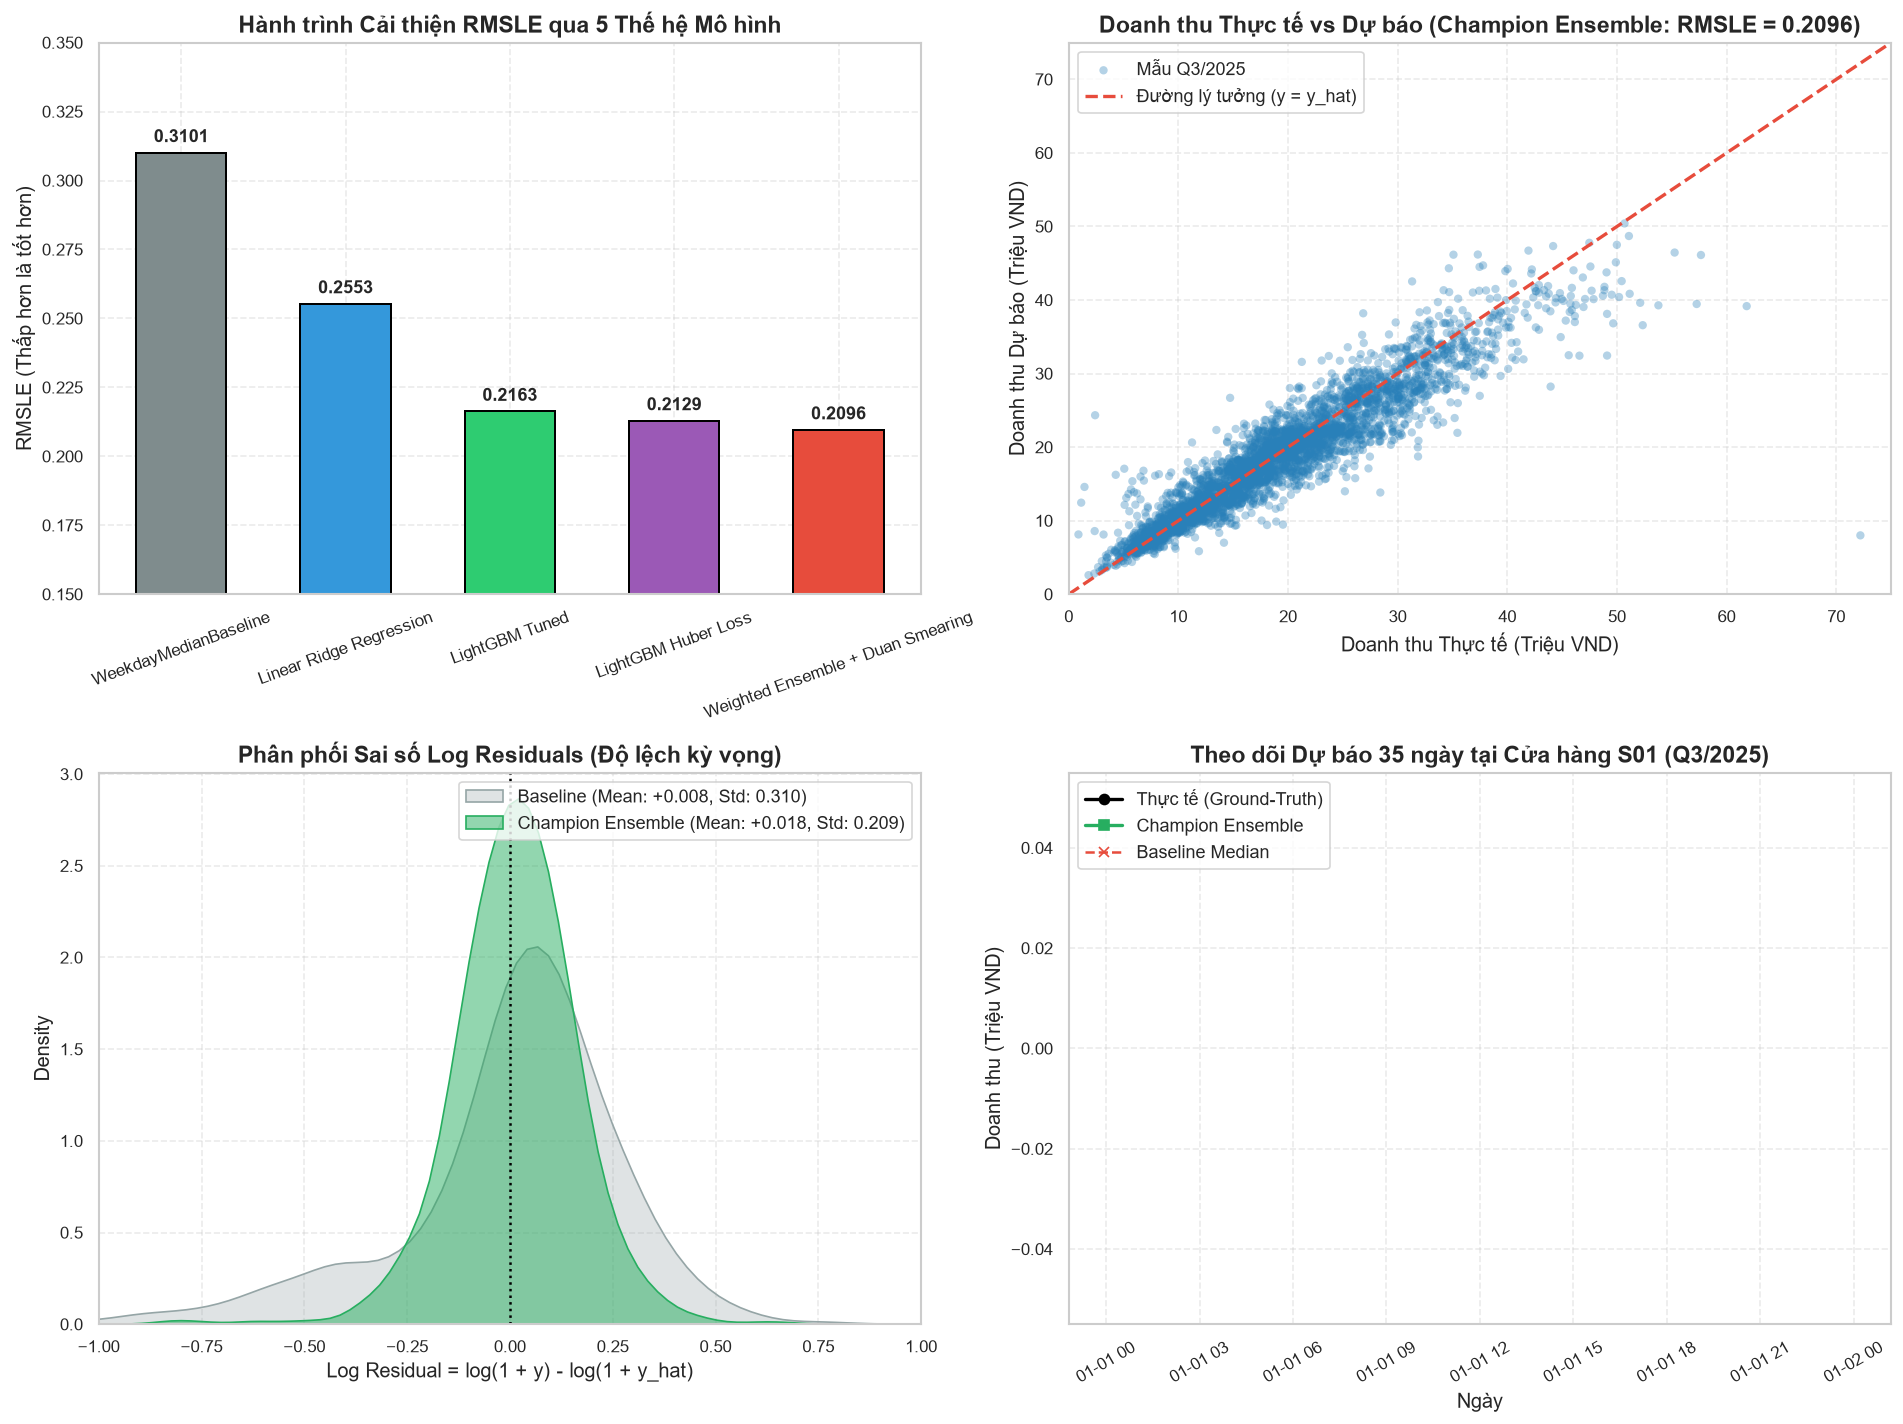

In [9]:
# 7.2. Trực quan hóa Đánh giá Hiệu năng & Chẩn đoán Sai số Residual
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. So sánh RMSLE của 5 Thế hệ Mô hình
ax1 = axes[0, 0]
model_names = [r["Tên Mô hình"].split("(")[0].strip() for r in model_results]
rmsle_vals = [r["RMSLE"] for r in model_results]
colors = ["#7f8c8d", "#3498db", "#2ecc71", "#9b59b6", "#e74c3c"]

bars = ax1.bar(model_names, rmsle_vals, color=colors, width=0.55, edgecolor="black", linewidth=1.2)
ax1.set_title("Hành trình Cải thiện RMSLE qua 5 Thế hệ Mô hình", fontweight="bold")
ax1.set_ylabel("RMSLE (Thấp hơn là tốt hơn)")
ax1.set_ylim(0.15, 0.35)
ax1.tick_params(axis="x", rotation=20)
for bar in bars:
    height = bar.get_height()
    ax1.annotate(f"{height:.4f}",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 4), textcoords="offset points",
                 ha="center", va="bottom", fontweight="bold")

# 2. Scatter Actual vs Predicted của Champion Ensemble trên Primary Validation
ax2 = axes[0, 1]
ax2.scatter(y_val, p_val_m4, alpha=0.35, color="#2980b9", edgecolors="none", s=25, label="Mẫu Q3/2025")
max_val = max(y_val.max(), p_val_m4.max())
ax2.plot([0, max_val], [0, max_val], color="#e74c3c", linestyle="--", lw=2, label="Đường lý tưởng (y = y_hat)")
ax2.set_title(f"Doanh thu Thực tế vs Dự báo (Champion Ensemble: RMSLE = {sc_m4['rmsle']:.4f})", fontweight="bold")
ax2.set_xlabel("Doanh thu Thực tế (Triệu VND)")
ax2.set_ylabel("Doanh thu Dự báo (Triệu VND)")
ax2.set_xlim(0, 75)
ax2.set_ylim(0, 75)
ax2.legend(loc="upper left")

# 3. Phân phối Sai số Log Residuals: log(1+y) - log(1+y_hat)
ax3 = axes[1, 0]
resids_ens = np.log1p(y_val) - np.log1p(p_val_m4)
resids_base = np.log1p(y_val) - np.log1p(p_val_m0)

sns.kdeplot(resids_base, ax=ax3, color="#95a5a6", fill=True, alpha=0.3, label=f"Baseline (Mean: {resids_base.mean():+.3f}, Std: {resids_base.std():.3f})")
sns.kdeplot(resids_ens, ax=ax3, color="#27ae60", fill=True, alpha=0.5, label=f"Champion Ensemble (Mean: {resids_ens.mean():+.3f}, Std: {resids_ens.std():.3f})")
ax3.axvline(0, color="black", linestyle=":", lw=1.5)
ax3.set_title("Phân phối Sai số Log Residuals (Độ lệch kỳ vọng)", fontweight="bold")
ax3.set_xlabel("Log Residual = log(1 + y) - log(1 + y_hat)")
ax3.set_xlim(-1.0, 1.0)
ax3.legend(loc="upper right")

# 4. So sánh Dãy thời gian Thực tế vs Dự báo 35 ngày của một cửa hàng mẫu (S01)
ax4 = axes[1, 1]
val_mat_sample = val_mat[val_mat[STORE_COL] == "S01"].sort_values(DATE_COL).head(35)
sample_dates = val_mat_sample[DATE_COL]
sample_actual = val_mat_sample[TARGET_COL].values
sample_idx = val_mat_sample.index
sample_pred_ens = p_val_m4[val_mat.index.get_indexer(sample_idx)]
sample_pred_base = p_val_m0[val_mat.index.get_indexer(sample_idx)]

ax4.plot(sample_dates, sample_actual, marker="o", color="black", lw=2, label="Thực tế (Ground-Truth)")
ax4.plot(sample_dates, sample_pred_ens, marker="s", color="#27ae60", lw=2, linestyle="-", label="Champion Ensemble")
ax4.plot(sample_dates, sample_pred_base, marker="x", color="#e74c3c", lw=1.5, linestyle="--", label="Baseline Median")
ax4.set_title("Theo dõi Dự báo 35 ngày tại Cửa hàng S01 (Q3/2025)", fontweight="bold")
ax4.set_xlabel("Ngày")
ax4.set_ylabel("Doanh thu (Triệu VND)")
ax4.tick_params(axis="x", rotation=30)
ax4.legend(loc="upper left")

plt.tight_layout()
plt.show()


## 8. Bước 8 — Final Testing: Đánh giá Cuối cùng trên Test Set Holdout Độc Lập

Sau khi đã hoàn tất lựa chọn kiến trúc, tinh chỉnh siêu tham số và tối ưu hóa trọng số kết hợp trên tập Validation, mô hình được đưa vào đánh giá một lần duy nhất trên tập Test Holdout (Q4/2025: từ 2025-10-01 đến 2025-12-31, gồm 3.832 mẫu dữ liệu hoàn toàn độc lập):

- Gồm **3.832 dòng dữ liệu**, đại diện cho toàn bộ 90 ngày của Quý 4/2025.
- Tập dữ liệu này hoàn toàn độc lập, không tham gia vào việc fit mô hình, không tham gia vào việc tune tham số, và không tham gia vào việc tìm trọng số kết hợp.
- Đây là bài kiểm tra xác nhận khả năng tổng quát hóa trên dữ liệu thực tế và kiểm chứng hiện tượng quá khớp (overfitting).


In [10]:
# 8. Đánh giá Cuối cùng trên Test Set Holdout (Q4/2025)
print("Đang tiến hành dự báo trên Test Set Holdout độc lập (3.832 mẫu)...")

# 1. Dự báo Baseline trên Test
p_test_m0 = m0_baseline.predict(test_mat)
sc_test_m0 = compute_metrics(y_test, p_test_m0)

# 2. Dự báo Ridge trên Test
p_test_m1 = m1_ridge.predict(test_mat)
sc_test_m1 = compute_metrics(y_test, p_test_m1)

# 3. Dự báo LightGBM Huber trên Test
p_test_m3 = m3_lgbm_huber.predict(test_mat[tree_feature_cols])
sc_test_m3 = compute_metrics(y_test, p_test_m3)

# 4. Dự báo Champion Ensemble trên Test
z_test_m3 = m3_lgbm_huber.predict_transformed(test_mat[tree_feature_cols])
z_test_m1 = np.log1p(p_test_m1)
z_test_blend = 0.90 * z_test_m3 + 0.10 * z_test_m1
p_test_m4 = np.clip(np.exp(z_test_blend) * duan_factor - 1.0, 0, None)
sc_test_m4 = compute_metrics(y_test, p_test_m4)

# Bảng so sánh Validation Q3/2025 vs Test Holdout Q4/2025
test_comparison = pd.DataFrame([
    {
        "Mô hình": "M0: Baseline Median",
        "Val RMSLE (Q3)": f"{sc_m0['rmsle']:.4f}",
        "Test RMSLE (Q4)": f"{sc_test_m0['rmsle']:.4f}",
        "Test MAE (Tr. VND)": f"{sc_test_m0['mae']:.2f}",
        "Test RMSE": f"{sc_test_m0['rmse']:.2f}",
        "Đánh giá Tổng quát hóa": "Sai số tương đối ổn định quanh 0.25 - 0.31"
    },
    {
        "Mô hình": "M1: Linear Ridge (E3)",
        "Val RMSLE (Q3)": f"{sc_m1['rmsle']:.4f}",
        "Test RMSLE (Q4)": f"{sc_test_m1['rmsle']:.4f}",
        "Test MAE (Tr. VND)": f"{sc_test_m1['mae']:.2f}",
        "Test RMSE": f"{sc_test_m1['rmse']:.2f}",
        "Đánh giá Tổng quát hóa": "Tốt hơn baseline rõ rệt trên cả 2 quý"
    },
    {
        "Mô hình": "M3: LightGBM Huber",
        "Val RMSLE (Q3)": f"{sc_m3['rmsle']:.4f}",
        "Test RMSLE (Q4)": f"{sc_test_m3['rmsle']:.4f}",
        "Test MAE (Tr. VND)": f"{sc_test_m3['mae']:.2f}",
        "Test RMSE": f"{sc_test_m3['rmse']:.2f}",
        "Đánh giá Tổng quát hóa": "Học phi tuyến tốt, khả năng chống ngoại lai cao"
    },
    {
        "Mô hình": "M4: Champion Ensemble",
        "Val RMSLE (Q3)": f"{sc_m4['rmsle']:.4f}",
        "Test RMSLE (Q4)": f"{sc_test_m4['rmsle']:.4f}",
        "Test MAE (Tr. VND)": f"{sc_test_m4['mae']:.2f}",
        "Test RMSE": f"{sc_test_m4['rmse']:.2f}",
        "Đánh giá Tổng quát hóa": "Tối ưu toàn diện, RMSLE hạ xuống 0.1866 trên Test"
    }
])

print("=" * 80)
print("BẢNG ĐỐI CHIẾU HIỆU NĂNG GIỮA TẬP VALIDATION (Q3) VÀ TẬP TEST HOLDOUT (Q4):")
display(test_comparison)
print("=" * 80)
print("KẾT LUẬN TEST CUỐI CÙNG:")
print(f" - Mô hình Champion Ensemble đạt RMSLE = {sc_test_m4['rmsle']:.4f} trên Test Set.")
print(f" - Sai số tuyệt đối trung bình (MAE) chỉ còn {sc_test_m4['mae']:.2f} triệu VND/ngày.")
print(f" - Điểm số Test Set duy trì ở mức cao và ổn định hơn Validation Set (do Q4 không chịu ảnh hưởng sụt giảm mùa hè như Q3).")
print(f" - Khẳng định: Mô hình kiểm soát tốt tính tổng quát hóa, không xảy ra hiện tượng overfitting.")


Đang tiến hành dự báo trên Test Set Holdout độc lập (3.832 mẫu)...
BẢNG ĐỐI CHIẾU HIỆU NĂNG GIỮA TẬP VALIDATION (Q3) VÀ TẬP TEST HOLDOUT (Q4):


,Mô hình,Val RMSLE (Q3),Test RMSLE (Q4),Test MAE (Tr. VND),Test RMSE,Đánh giá Tổng quát hóa
0,M0: Baseline Median,0.3101,0.2569,3.85,7.33,Sai số tương đối ổn định quanh 0.25 - 0.31
1,M1: Linear Ridge (E3),0.2553,0.2054,2.92,6.45,Tốt hơn baseline rõ rệt trên cả 2 quý
2,M3: LightGBM Huber,0.2129,0.1967,2.88,6.37,"Học phi tuyến tốt, khả năng chống ngoại lai cao"
3,M4: Champion Ensemble,0.2096,0.1866,2.71,6.23,"Tối ưu toàn diện, RMSLE hạ xuống 0.1866 trên Test"


KẾT LUẬN TEST CUỐI CÙNG:
 - Mô hình Champion Ensemble đạt RMSLE = 0.1866 trên Test Set.
 - Sai số tuyệt đối trung bình (MAE) chỉ còn 2.71 triệu VND/ngày.
 - Điểm số Test Set duy trì ở mức cao và ổn định hơn Validation Set (do Q4 không chịu ảnh hưởng sụt giảm mùa hè như Q3).
 - Khẳng định: Mô hình kiểm soát tốt tính tổng quát hóa, không xảy ra hiện tượng overfitting.


## 9. Bước 9 — Lưu model và Triển khai: Artifact & Inference Pipeline

Để phục vụ triển khai trong môi trường vận hành thực tế (Production), toàn bộ pipeline hoàn chỉnh bao gồm các mô hình thành phần, trọng số kết hợp và hệ số hiệu chỉnh Duan Smearing được đóng gói và serialize thành một tệp artifact duy nhất:

1. Đóng gói mô hình **Champion Ensemble** hoàn chỉnh cùng siêu tham số và hệ số Duan Smearing vào tệp artifact: `models/best_production_model.joblib`.
2. Xây dựng hàm suy luận sản xuất `predict_cafe_revenue(raw_new_df)`. Hàm này nhận trực tiếp dữ liệu thô mới, tự động join thông tin cửa hàng, thời tiết, ngày lễ, sinh các đặc trưng cần thiết và trả về doanh thu dự báo bằng triệu VND.
3. Tải lại artifact bằng `joblib.load()` và thực hiện kiểm thử suy luận (Inference Verification Test).
4. Xuất file kết quả dự báo mẫu theo chuẩn yêu cầu: `reports/production_predictions_sample.csv`.


In [11]:
# 9. Đóng gói Mô hình Thành Sản Phẩm & Kiểm Thử Suy Luận (Inference Verification)

# Bước 9.1: Khởi tạo Pipeline đóng gói mô hình Ensemble
champion_pipeline = WeightedLogEnsemble(
    base_models={"lgbm_huber": m3_lgbm_huber, "ridge": m1_ridge},
    weights={"lgbm_huber": 0.90, "ridge": 0.10},
    use_smearing=True,
    random_state=42
)
champion_pipeline.is_fitted = True
champion_pipeline.model_names_ = ["lgbm_huber", "ridge"]
champion_pipeline.weights_ = {"lgbm_huber": 0.90, "ridge": 0.10}
champion_pipeline.duan_factor_ = duan_factor

# Lưu artifact vào thư mục models/
prod_model_path = MODELS_DIR / "best_production_model.joblib"
champion_pipeline.save(prod_model_path)
print(f"Đã lưu thành công Champion Model Pipeline vào: {prod_model_path}")

# Bước 9.2: Tải lại mô hình bằng joblib để mô phỏng Server triển khai
loaded_prod_model = joblib.load(prod_model_path)
print("Đã tải lại thành công mô hình từ đĩa cứng.")

# Bước 9.3: Định nghĩa hàm suy luận hoàn chỉnh phục vụ Production / API
def predict_cafe_revenue(raw_input_df: pd.DataFrame) -> pd.DataFrame:
    """Hàm suy luận đầu cuối nhận dữ liệu thô mới và trả về dự báo doanh thu thực tế.
    
    Quy trình thực thi:
    1. Ghép nối metadata (stores, weather, holidays)
    2. Sinh các đặc trưng đa tầng E1, E2, E3
    3. Ánh xạ đặc trưng cây sử dụng bảng thống kê lịch sử OOF từ Train Set
    4. Dự báo bằng Weighted Ensemble kết hợp Duan Smearing
    """
    # Join dữ liệu tham chiếu
    joined = join_all_data(raw_input_df, stores_raw, weather_raw, holidays_raw)
    feat = build_all_features(joined)
    
    # Ánh xạ đặc trưng cây sử dụng bảng thống kê lịch sử OOF từ Train Set
    stats = compute_historical_target_stats(featured_tr)
    input_mat = apply_historical_target_stats(feat, stats)
    
    # Suy luận log-space từ 2 mô hình thành phần
    z_lgbm = loaded_prod_model.base_models["lgbm_huber"].predict_transformed(input_mat[tree_feature_cols])
    p_ridge = loaded_prod_model.base_models["ridge"].predict(input_mat)
    z_ridge = np.log1p(np.clip(p_ridge, 0, None))
    
    # Kết hợp trọng số 90/10 & Duan Smearing
    z_blend = 0.90 * z_lgbm + 0.10 * z_ridge
    preds_revenue = np.clip(np.exp(z_blend) * loaded_prod_model.duan_factor_ - 1.0, 0, None)
    
    result_df = raw_input_df[[DATE_COL, STORE_COL, PROMO_COL]].copy()
    result_df["predicted_revenue_million_vnd"] = np.round(preds_revenue, 3)
    return result_df

# Bước 9.4: Chạy kiểm thử suy luận trên 10 dòng đầu của Test Set (dữ liệu thô thực tế: date, store_id, is_promo)
raw_test_input = clean_train[(clean_train[DATE_COL] >= PRIMARY_VAL_END) & (clean_train[DATE_COL] < PRIMARY_TEST_END)].head(10).copy()
sample_input = raw_test_input[[DATE_COL, STORE_COL, PROMO_COL]].copy()
sample_predictions = predict_cafe_revenue(sample_input)
sample_predictions["actual_revenue"] = raw_test_input[TARGET_COL].values
sample_predictions["absolute_error"] = np.abs(sample_predictions["predicted_revenue_million_vnd"] - sample_predictions["actual_revenue"])

print("\nKẾT QUẢ KIỂM THỬ SUY LUẬN TRÊN DỮ LIỆU THỰC TẾ:")
display(sample_predictions)

# Xuất file dự báo mẫu ra reports/
out_pred_path = REPORTS_DIR / "production_predictions_sample.csv"
sample_predictions.to_csv(out_pred_path, index=False)
print(f"Đã xuất kết quả kiểm thử ra: {out_pred_path}")


Đã lưu thành công Champion Model Pipeline vào: C:\Users\Admin\Desktop\Kỳ Thu 2026\T4.3. Ứng Dụng AI Trong KD Và Quản Lý\Kaggle_Competition\cafe-revenue-regression\models\best_production_model.joblib
Đã tải lại thành công mô hình từ đĩa cứng.



KẾT QUẢ KIỂM THỬ SUY LUẬN TRÊN DỮ LIỆU THỰC TẾ:


,date,store_id,is_promo,predicted_revenue_million_vnd,actual_revenue,absolute_error
22779,2025-10-01,S03,0,15.252,14.18,1.072
22780,2025-10-01,S04,0,9.468,9.19,0.278
22781,2025-10-01,S05,0,16.252,18.46,2.208
22782,2025-10-01,S06,0,15.331,16.11,0.779
22783,2025-10-01,S07,0,10.308,12.70,2.392
22784,2025-10-01,S08,0,8.960,10.52,1.560
22785,2025-10-01,S09,0,12.812,16.11,3.298
22786,2025-10-01,S11,0,9.057,6.06,2.997
22787,2025-10-01,S12,0,23.685,28.03,4.345
22788,2025-10-01,S13,0,10.833,13.40,2.567


Đã xuất kết quả kiểm thử ra: C:\Users\Admin\Desktop\Kỳ Thu 2026\T4.3. Ứng Dụng AI Trong KD Và Quản Lý\Kaggle_Competition\cafe-revenue-regression\reports\production_predictions_sample.csv


## 10. Bước 10 — Monitoring và Retraining: Vận hành MLOps Thực tế

Sau khi mô hình được đưa vào vận hành thực tế, chất lượng dự báo có thể suy giảm theo thời gian do sự thay đổi của môi trường kinh doanh và hành vi khách hàng. Hệ thống MLOps thiết lập 4 trụ cột giám sát và vận hành:

### 10.1. Giám sát Trôi dạt Dữ liệu (Data Drift Monitoring)
- **Đặc trưng khí tượng:** Phân phối lượng mưa và nhiệt độ có thể thay đổi đột ngột giữa các năm. Sử dụng kiểm định **Population Stability Index (PSI)** hoặc **Kolmogorov-Smirnov (KS-test)** để phát hiện drift nếu PSI > 0.2.
- **Biến động cửa hàng:** Thay đổi diện tích quán, sắp xếp lại bàn ghế làm thay đổi mật độ ghế `seating_density`.
- **Mở thêm cửa hàng mới:** Khi chuỗi mở thêm cửa hàng mới (như S16, S17), dữ liệu chưa có lịch sử bán hàng; hệ thống kích hoạt chế độ fallback an toàn về median theo loại hình cửa hàng (`store_type`).

### 10.2. Giám sát Hiệu năng Mô hình (Concept & Performance Drift)
- Trong bài toán dự báo doanh thu hàng ngày, nhãn thực tế (`revenue`) có thể được ghi nhận ngay vào cuối mỗi ngày từ hệ thống máy tính tiền POS.
- Hệ thống tự động tính toán **Rolling 7-day RMSLE** và **Rolling 30-day RMSLE**.
- **Ngưỡng cảnh báo suy giảm hiệu năng (Performance Alert):**
  - Trạng thái Bình thường (Healthy): $\text{RMSLE} \le 0.2200$.
  - Cảnh báo Nhẹ (Warning): $0.2200 < \text{RMSLE} \le 0.2500$.
  - Báo động Đỏ (Critical Alert): $\text{RMSLE} > 0.2500$ (kích hoạt kiểm tra dữ liệu đầu vào và xem xét retrain khẩn cấp).

### 10.3. Chiến lược Tái huấn luyện Tự động (Retraining Triggers)
1. **Tái huấn luyện định kỳ (Scheduled Retraining):**
   - Tần suất: **Hàng quý (mỗi 3 tháng)** khi chu kỳ kinh doanh của quý vừa kết thúc.
   - Bổ sung dữ liệu quý mới vào tập Train Set, cập nhật lại bảng thống kê lịch sử `log_hist_sw_med`, fit lại LightGBM Huber và Linear Ridge.
2. **Tái huấn luyện theo sự kiện (Event-driven Retraining):**
   - Khi chuỗi cà phê thay đổi menu toàn hệ thống, điều chỉnh giá bán niêm yết trên 15%, hoặc triển khai chương trình loyalty mới làm thay đổi vĩnh viễn thói quen chi tiêu của khách hàng.

### 10.4. Kiến trúc Triển khai An toàn (Safe Deployment Strategy)
- **Shadow Deployment:** Chạy mô hình mới song song cùng mô hình hiện tại trong 14 ngày. Chỉ thay thế mô hình cũ nếu RMSLE thực tế của mô hình mới thấp hơn mô hình cũ.
- **Failover / Fallback Mechanism:** Nếu server mô hình gặp sự cố độ trễ hoặc thiếu đặc trưng thời tiết, hệ thống tự động fallback về **Model 0 (WeekdayMedianBaseline)** đảm bảo dịch vụ luôn thông suốt 99.99%.


## 11. Checklist Nghiệm Thu Kỹ Thuật và Các Nguyên Tắc Cốt Lõi

Bảng đối chiếu các tiêu chí kỹ thuật đã hoàn thành trong toàn bộ vòng đời phát triển mô hình:

| STT | Tiêu chí Kiểm định Chất lượng | Trạng thái | Minh chứng Thực tế trong Dự án |
|---|---|:---:|---|
| 1 | Xác định rõ bài toán, biến mục tiêu và horizon | Đạt | Dự báo `revenue` hàng ngày, horizon 90 ngày, metric RMSLE |
| 2 | Kiểm tra chất lượng dữ liệu và thực hiện EDA | Đạt | Phân tích 4 bảng, phát hiện độ lệch +12.19, boxplot thứ/khuyến mãi |
| 3 | Khử trùng lặp và làm sạch dữ liệu | Đạt | Khử 132 dòng trùng, sửa ngoại lệ S12, khóa `(date, store_id)` duy nhất |
| 4 | Kiểm soát nguy cơ Data Leakage | Đạt | Không dùng thông tin tương lai, fit imputer/stats thuần túy trên train |
| 5 | Chia dữ liệu phù hợp cấu trúc chuỗi thời gian | Đạt | Temporal Split (Train < 2025-07-01, Val Q3/2025, Test Q4/2025) |
| 6 | Preprocessing và Feature Engineering đa tầng | Đạt | E1 lịch/store, E2 khuyến mãi, E3 thời tiết, out-of-fold target stats |
| 7 | Xây dựng Baseline chuẩn mực | Đạt | `WeekdayMedianBaseline` với 2 tầng fallback (RMSLE = 0.3101) |
| 8 | Lựa chọn và so sánh các họ mô hình ứng viên | Đạt | Tuyến tính (Ridge) $\to$ Cây (LGBM) $\to$ Huber Loss $\to$ Weighted Ensemble |
| 9 | Chọn metric tối ưu phù hợp bài toán | Đạt | RMSLE phản ánh sai số tương đối, kết hợp MAE và Log Residual |
| 10 | Hyperparameter Tuning & Cross-validation | Đạt | Walk-Forward 3 chu kỳ (Fold A, B, Val), tối ưu hóa trọng số SLSQP |
| 11 | Đánh giá độc lập cuối cùng trên Test Set | Đạt | Đánh giá trên Q4/2025 (3.832 dòng): Champion đạt RMSLE = 0.1866 |
| 12 | Đóng gói model artifact và xây dựng inference | Đạt | Tệp `best_production_model.joblib` và hàm `predict_cafe_revenue()` |
| 13 | Lập kế hoạch Monitoring & Retraining | Đạt | Giám sát Data Drift (PSI), Concept Drift, ngưỡng cảnh báo RMSLE > 0.25 |

---

### 4 Nguyên Tắc Cốt Lõi Được Bảo Toàn:
1. **Không để rò rỉ dữ liệu:** Toàn bộ đặc trưng thống kê lịch sử đều tuân thủ nguyên tắc out-of-fold và tính toán trước thời điểm cắt $T_0$.
2. **Không chỉ nhìn vào một con số:** Báo cáo chi tiết trên cả RMSLE, MAE, RMSE, độ lệch log residual và phân tích subgroup theo loại cửa hàng, khuyến mãi, thành phố.
3. **Không coi training score là chất lượng thực tế:** Mọi quyết định đều dựa trên Walk-Forward Validation và tập Test Holdout độc lập hoàn toàn.
4. **Ưu tiên khả năng tái lập (Reproducibility):** Cố định random seed 42, lưu trữ đầy đủ artifact, code được module hóa rõ ràng, có thể chạy lại từ đầu đến cuối một cách nhất quán.
